# DNA/RNA language project: Tasks 1 and 2

Continues from the dataset builder notebook (`dataset.csv`).

**Task 1:** turn each 1000 bp fragment into a "sentence" of overlapping k-mer "words" and build Bag-of-Words matrices (k = 3, 4, 6, plus 8 for the size comparison).
**Task 2:** explore the k-mer language (word frequencies, rare words, class differences) and test whether the classes cluster (PCA, with optional t-SNE at the end), with a GC-content confound check.

No reverse complement is used: k-mers are read on the strand as stored.

In [1]:
import os, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse, stats
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams["figure.dpi"] = 110

CANDIDATES = ["/content/dna_dataset/dataset.csv",
              "/content/drive/MyDrive/dna_dataset/dataset.csv",
              "dataset.csv"]
path = next((p for p in CANDIDATES if os.path.exists(p)), None)
if path is None:
    from google.colab import drive
    drive.mount("/content/drive")
    path = next((p for p in CANDIDATES if os.path.exists(p)), None)
if path is None:
    raise FileNotFoundError("dataset.csv not found. Run the builder notebook first or upload the file.")

df = pd.read_csv(path)
print(path, df.shape)
display(df.drop(columns="sequence").head())
print(df.groupby("label_name").genome_id.nunique().to_dict(), "genomes per class")
print(df.groupby("genome_id").size().describe()[["min", "max"]].to_dict(), "fragments per genome")

Mounted at /content/drive
/content/drive/MyDrive/dna_dataset/dataset.csv (9600, 11)


,fragment_id,genome_id,genus,organism,label,label_name,start,length,gc,split_suggested
0,NC_007530.2_4271000,NC_007530.2,Bacillus,Bacillus anthracis Ames,1,pathogen,4271000,1000,0.384,train
1,NC_007530.2_5140000,NC_007530.2,Bacillus,Bacillus anthracis Ames,1,pathogen,5140000,1000,0.364,train
2,NC_007530.2_4321000,NC_007530.2,Bacillus,Bacillus anthracis Ames,1,pathogen,4321000,1000,0.387,train
3,NC_007530.2_3319000,NC_007530.2,Bacillus,Bacillus anthracis Ames,1,pathogen,3319000,1000,0.398,train
4,NC_007530.2_4755000,NC_007530.2,Bacillus,Bacillus anthracis Ames,1,pathogen,4755000,1000,0.413,train


{'non_pathogen': 12, 'pathogen': 12} genomes per class
{'min': 400.0, 'max': 400.0} fragments per genome


## Task 1: sequences as sentences of k-mer words

A fragment of length L has L - k + 1 overlapping words (stride 1). scikit-learn's character n-gram analyser does exactly this, so `CountVectorizer(analyzer="char", ngram_range=(k, k))` is the tokenizer. The vocabulary is passed in explicitly (all 4^k words) so that words that never occur still get a column of zeros; otherwise "absent words" would be invisible.

In [2]:
def all_words(k):
    return ["".join(p) for p in itertools.product("ACGT", repeat=k)]

def kmer_tokens(seq, k):
    # explicit tokenizer, for illustration and for word2vec-style work in Task 3
    return [seq[i:i + k] for i in range(len(seq) - k + 1)]

demo = df.sequence.iloc[0]
print("first 10 4-mer tokens:", kmer_tokens(demo, 4)[:10])
print("tokens per fragment:", {k: len(kmer_tokens(demo, k)) for k in (3, 4, 6, 8)})

def build_counts(k):
    cv = CountVectorizer(analyzer="char", ngram_range=(k, k), lowercase=False,
                         vocabulary=all_words(k), dtype=np.int32)
    return cv.fit_transform(df.sequence)          # sparse (n_fragments x 4^k)

KS = [3, 4, 6, 8]
COUNTS = {k: build_counts(k) for k in KS}
for k in KS:
    print(f"k={k}: matrix {COUNTS[k].shape}, nnz={COUNTS[k].nnz:,}")

first 10 4-mer tokens: ['ACGA', 'CGAA', 'GAAC', 'AACA', 'ACAT', 'CATT', 'ATTT', 'TTTT', 'TTTC', 'TTCA']
tokens per fragment: {3: 998, 4: 997, 6: 995, 8: 993}
k=3: matrix (9600, 64), nnz=609,345
k=4: matrix (9600, 256), nnz=2,196,959
k=6: matrix (9600, 4096), nnz=7,675,150
k=8: matrix (9600, 65536), nnz=9,291,385


### Effect of k

Larger k captures longer motifs but the vocabulary grows by 4x per step, so each 1000 bp fragment fills a smaller and smaller part of it.

,k,vocab_size,tokens_per_fragment,mean_distinct_words_per_fragment,fragment_vector_sparsity,corpus_words_used,corpus_words_absent,mean_count_per_word,tokens_per_vocab_word_per_fragment
0,3,64,998,63.5,0.008,64,0,149700.0,15.594
1,4,256,997,228.8,0.106,256,0,37387.5,3.895
2,6,4096,995,799.5,0.805,4096,0,2332.0,0.243
3,8,65536,993,967.9,0.985,65536,0,145.5,0.015


,k,vocab_size,mean_distinct_words_per_fragment,fragment_vocab_usage_pct
0,3,64,63.5,99.2
1,4,256,228.8,89.4
2,6,4096,799.5,19.5
3,8,65536,967.9,1.5


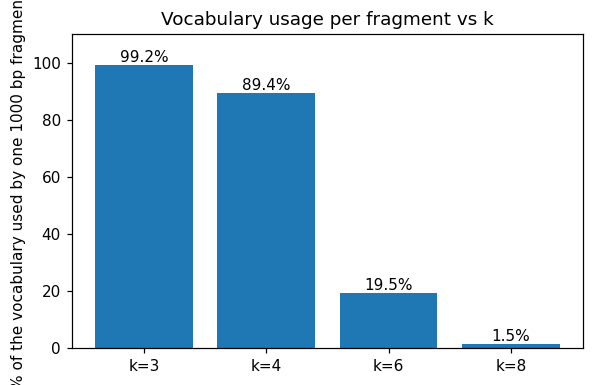

In [3]:
rows = []
for k in KS:
    X = COUNTS[k]
    V = 4 ** k
    tokens_per_frag = X.sum(axis=1).A1
    distinct_per_frag = np.diff(X.tocsr().indptr)
    corpus = np.asarray(X.sum(axis=0)).ravel()
    rows.append(dict(k=k, vocab_size=V,
                     tokens_per_fragment=int(tokens_per_frag.mean()),
                     mean_distinct_words_per_fragment=round(distinct_per_frag.mean(), 1),
                     fragment_vector_sparsity=round(1 - distinct_per_frag.mean() / V, 3),
                     corpus_words_used=int((corpus > 0).sum()),
                     corpus_words_absent=int((corpus == 0).sum()),
                     mean_count_per_word=round(corpus.mean(), 1),
                     tokens_per_vocab_word_per_fragment=round(tokens_per_frag.mean() / V, 3)))
k_table = pd.DataFrame(rows)
display(k_table)

k_table["fragment_vocab_usage_pct"] = (100 * k_table.mean_distinct_words_per_fragment / k_table.vocab_size).round(1)
display(k_table[["k", "vocab_size", "mean_distinct_words_per_fragment", "fragment_vocab_usage_pct"]])

fig, ax = plt.subplots(figsize=(5.5, 3.6))
bars = ax.bar([f"k={k}" for k in k_table.k], k_table.fragment_vocab_usage_pct, color="tab:blue")
ax.bar_label(bars, fmt="%.1f%%")
ax.set_ylabel("% of the vocabulary used by one 1000 bp fragment")
ax.set_ylim(0, 110)
ax.set_title("Vocabulary usage per fragment vs k")
plt.tight_layout(); plt.show()

### Bag-of-Words matrices used in Task 2

Dense frequency matrices (counts divided by tokens per fragment) for k = 4 (256 words) and k = 6 (4096 words). Frequencies, not raw counts, so every fragment is on the same scale.

In [4]:
def to_freq(X):
    X = X.astype(np.float32)
    s = np.asarray(X.sum(axis=1)).ravel()[:, None]
    return np.asarray(X.todense() / s, dtype=np.float32)

FREQ = {k: to_freq(COUNTS[k]) for k in (4, 6)}
VOCAB = {k: np.array(all_words(k)) for k in (3, 4, 6, 8)}
y = df.label.values
genome = df.genome_id.values
genus = df.genus.values
gc = df.gc.values
print({k: v.shape for k, v in FREQ.items()})

{4: (9600, 256), 6: (9600, 4096)}


## Task 2: explore the sequence language

### Corpus-wide word frequencies (4-mers and 6-mers)


===== k=4: 256 words, 0 never occur, total tokens 9,571,200, mean count 37388
Top 20:


,word,count,freq
0,AAAA,93313,0.009749
1,TTTT,93192,0.009737
2,AAAT,66805,0.006980
3,ATTT,66556,0.006954
4,GCCG,65572,0.006851
5,CGGC,65012,0.006792
6,CGCC,63455,0.006630
7,GGCG,63132,0.006596
8,GCGC,59210,0.006186
9,AATT,57440,0.006001


Bottom 20:


,word,count,freq
236,CTCT,23150,0.002419
237,CGTA,23068,0.002410
238,TACG,22813,0.002384
239,AGAC,22548,0.002356
240,AGAG,22351,0.002335
241,GTCT,22317,0.002332
242,GACT,22213,0.002321
243,TCTA,22204,0.002320
244,TAGA,22053,0.002304
245,AGTC,21906,0.002289



===== k=6: 4096 words, 0 never occur, total tokens 9,552,000, mean count 2332
Top 20:


,word,count,freq
0,TTTTTT,9926,0.001039
1,AAAAAA,9874,0.001034
2,AAAAAT,9128,0.000956
3,ATTTTT,8749,0.000916
4,GAAAAA,7917,0.000829
5,TTTTTA,7914,0.000829
6,TAAAAA,7912,0.000828
7,TTTTTC,7766,0.000813
8,CTTTTT,7491,0.000784
9,CGCCGC,7293,0.000764


Bottom 20:


,word,count,freq
4076,CTTAGG,686,0.000072
4077,CCCTAG,666,0.000070
4078,CTAGGA,656,0.000069
4079,CTAGAG,649,0.000068
4080,CCTAGT,648,0.000068
4081,GTCCTA,639,0.000067
4082,CCTAGA,639,0.000067
4083,TCCTAG,636,0.000067
4084,GACTAG,631,0.000066
4085,CTAGGT,621,0.000065


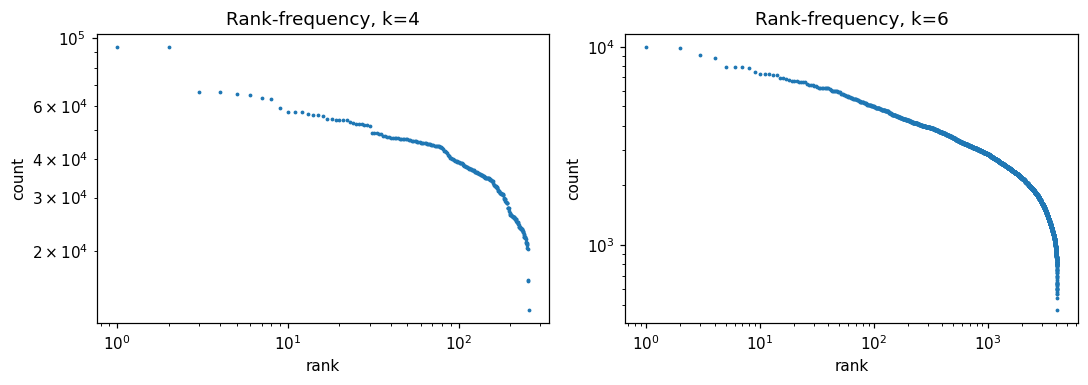

In [5]:
def corpus_table(k):
    c = np.asarray(COUNTS[k].sum(axis=0)).ravel()
    t = pd.DataFrame({"word": VOCAB[k], "count": c})
    t["freq"] = t["count"] / t["count"].sum()
    return t.sort_values("count", ascending=False).reset_index(drop=True)

CORPUS = {k: corpus_table(k) for k in (4, 6)}
for k in (4, 6):
    t = CORPUS[k]
    print(f"\n===== k={k}: {len(t)} words, {int((t['count']==0).sum())} never occur, "
          f"total tokens {t['count'].sum():,}, mean count {t['count'].mean():.0f}")
    print("Top 20:");    display(t.head(20))
    print("Bottom 20:"); display(t.tail(20))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for k, a in zip((4, 6), ax):
    t = CORPUS[k]; nz = t[t["count"] > 0]
    a.loglog(np.arange(1, len(nz) + 1), nz["count"].values, ".", ms=3)
    a.set_title(f"Rank-frequency, k={k}"); a.set_xlabel("rank"); a.set_ylabel("count")
plt.tight_layout(); plt.show()

### Per-fragment statistics

GC content, GC skew, and how many distinct words a fragment uses.

label_name            non_pathogen     pathogen
gc             count   4800.000000  4800.000000
               mean       0.507472     0.472731
               std        0.117365     0.114350
               min        0.256000     0.229000
               25%        0.406000     0.377000
               50%        0.498500     0.468000
               75%        0.606000     0.547000
               max        0.822000     0.804000
gc_skew        count   4800.000000  4800.000000
               mean      -0.001085     0.001434
               std        0.099968     0.116006
               min       -0.380117    -0.465798
               25%       -0.070758    -0.074084
               50%        0.001568     0.002083
               75%        0.065580     0.075440
               max        0.364341     0.400000
distinct_4mers count   4800.000000  4800.000000
               mean     227.983750   229.716042
               std       17.018779    13.312644
               min       44.000000   144.000000
               25%      222.000000   222.000000
               50%      233.000000   232.000000
               75%      239.000000   240.000000
               max      254.000000   254.000000
distinct_6mers count   4800.000000  4800.000000
               mean     799.748542   799.241042
               std       51.514248    49.314125
               min       91.000000   356.000000
               25%      778.000000   771.000000
               50%      811.000000   807.000000
               75%      834.000000   835.000000
               max      892.000000   901.000000

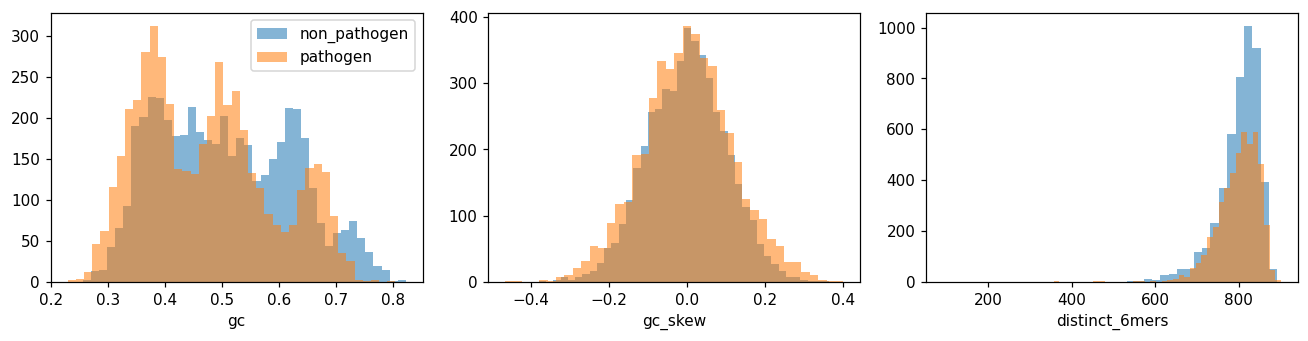

In [6]:
seqs = df.sequence
df["gc_skew"] = [(s.count("G") - s.count("C")) / max(1, s.count("G") + s.count("C")) for s in seqs]
df["distinct_4mers"] = np.diff(COUNTS[4].tocsr().indptr)
df["distinct_6mers"] = np.diff(COUNTS[6].tocsr().indptr)

display(df.groupby("label_name")[["gc", "gc_skew", "distinct_4mers", "distinct_6mers"]].describe().T)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for col, a in zip(["gc", "gc_skew", "distinct_6mers"], ax):
    for lab, name in ((0, "non_pathogen"), (1, "pathogen")):
        a.hist(df.loc[df.label == lab, col], bins=40, alpha=0.55, label=name)
    a.set_xlabel(col)
ax[0].legend(); plt.tight_layout(); plt.show()

### Which words differ between pathogens and non-pathogens?

Each genome contributes equally (word frequencies are averaged within a genome first, then compared across the 12 vs 12 genomes). `log2 ratio` is pathogen over non-pathogen. The p-values are nominal and uncorrected; with only 12 genomes per class and thousands of words, treat them as a ranking, not as proof.


===== k=4: words enriched in pathogens


,word,mean_pathogen,mean_non_pathogen,log2_ratio,p_value,gc_in_word
204,TATA,0.003189,0.002132,0.580821,0.253763,0.00
252,TTTA,0.006997,0.004926,0.506336,0.272191,0.00
192,TAAA,0.006981,0.004937,0.499707,0.279303,0.00
240,TTAA,0.005846,0.004289,0.446666,0.320728,0.00
48,ATAA,0.005667,0.004183,0.438022,0.294263,0.00
242,TTAG,0.003151,0.002352,0.421563,0.341660,0.25
12,AATA,0.005802,0.004337,0.419689,0.293976,0.00
112,CTAA,0.003131,0.002369,0.402109,0.359825,0.25
207,TATT,0.005823,0.004410,0.401013,0.314216,0.00
243,TTAT,0.005691,0.004311,0.400601,0.327964,0.00


===== k=4: words enriched in non-pathogens


,word,mean_pathogen,mean_non_pathogen,log2_ratio,p_value,gc_in_word
165,GGCC,0.003703,0.005458,-0.559843,0.341428,1.00
181,GTCC,0.001999,0.002944,-0.557844,0.118110,0.75
161,GGAC,0.002030,0.002976,-0.551343,0.138743,0.75
86,CCCG,0.002854,0.003917,-0.456776,0.396450,1.00
106,CGGG,0.002909,0.003985,-0.453936,0.397747,1.00
117,CTCC,0.002287,0.003125,-0.450055,0.079703,0.75
90,CCGG,0.004151,0.005663,-0.447899,0.431404,1.00
93,CCTC,0.002361,0.003191,-0.434663,0.207112,0.75
173,GGTC,0.002917,0.003903,-0.420123,0.253674,0.75
138,GAGG,0.002354,0.003144,-0.417379,0.220065,0.75



===== k=6: words enriched in pathogens


,word,mean_pathogen,mean_non_pathogen,log2_ratio,p_value,gc_in_word
3882,TTAGGG,0.000160,0.000084,0.914786,0.273379,0.500000
3276,TATATA,0.000216,0.000116,0.894346,0.244420,0.000000
3878,TTAGCG,0.000280,0.000151,0.884561,0.087963,0.500000
412,ACGCTA,0.000164,0.000089,0.881219,0.044895,0.500000
2460,GCGCTA,0.000227,0.000128,0.824877,0.006723,0.666667
3227,TAGCGT,0.000181,0.000102,0.819712,0.073734,0.500000
3131,TAATGT,0.000286,0.000162,0.809906,0.110754,0.166667
1648,CGCTAA,0.000246,0.000140,0.809092,0.085949,0.500000
3097,TAACGC,0.000273,0.000156,0.802584,0.066703,0.500000
1650,CGCTAG,0.000113,0.000065,0.793277,0.094432,0.666667


===== k=6: words enriched in non-pathogens


,word,mean_pathogen,mean_non_pathogen,log2_ratio,p_value,gc_in_word
2709,GGGCCC,0.000070,0.000156,-1.148051,0.261292,1.000000
1461,CCGTCC,0.000136,0.000265,-0.958778,0.193672,0.833333
2209,GAGGAC,0.000106,0.000206,-0.958613,0.141757,0.666667
2586,GGACGG,0.000148,0.000279,-0.913448,0.209675,0.833333
2213,GAGGCC,0.000142,0.000266,-0.898801,0.186603,0.833333
2781,GGTCTC,0.000088,0.000164,-0.892914,0.111395,0.666667
1686,CGGCCG,0.000341,0.000631,-0.887115,0.361059,1.000000
2725,GGGGCC,0.000107,0.000198,-0.879809,0.212180,1.000000
1701,CGGGCC,0.000200,0.000368,-0.874076,0.330979,1.000000
1734,CGTACG,0.000090,0.000163,-0.853491,0.287893,0.666667


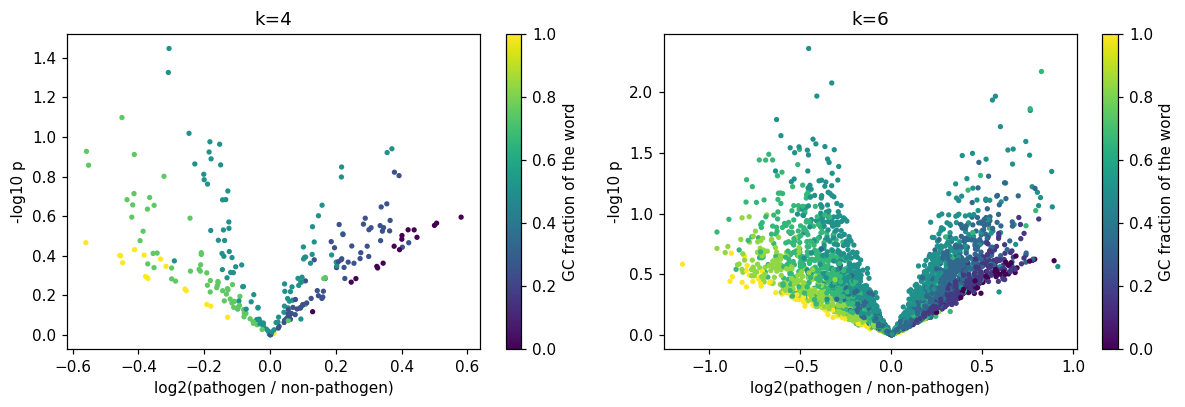

If enriched words are mostly AT-rich in one class and GC-rich in the other (colour pattern), the signal is mainly GC content.


In [7]:
def class_diff(k):
    F = pd.DataFrame(FREQ[k], columns=VOCAB[k])
    G = F.groupby(genome).mean()
    lab = df.groupby("genome_id").label.first().loc[G.index]
    P, N = G[lab == 1], G[lab == 0]
    eps = 1e-6
    out = pd.DataFrame({"word": G.columns,
                        "mean_pathogen": P.mean().values,
                        "mean_non_pathogen": N.mean().values})
    out["log2_ratio"] = np.log2((out.mean_pathogen + eps) / (out.mean_non_pathogen + eps))
    out["p_value"] = stats.ttest_ind(P.values, N.values, equal_var=False).pvalue
    out["gc_in_word"] = [sum(c in "GC" for c in w) / k for w in out.word]
    return out

DIFF = {k: class_diff(k) for k in (4, 6)}
for k in (4, 6):
    d = DIFF[k]
    print(f"\n===== k={k}: words enriched in pathogens"); display(d.sort_values("log2_ratio", ascending=False).head(10))
    print(f"===== k={k}: words enriched in non-pathogens"); display(d.sort_values("log2_ratio").head(10))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k, a in zip((4, 6), ax):
    d = DIFF[k]
    sc = a.scatter(d.log2_ratio, -np.log10(d.p_value.clip(lower=1e-300)), c=d.gc_in_word, s=6, cmap="viridis")
    a.set_title(f"k={k}"); a.set_xlabel("log2(pathogen / non-pathogen)"); a.set_ylabel("-log10 p")
    plt.colorbar(sc, ax=a, label="GC fraction of the word")
plt.tight_layout(); plt.show()
print("If enriched words are mostly AT-rich in one class and GC-rich in the other (colour pattern), the signal is mainly GC content.")

### Rare and common words relative to base composition

Expected frequency of a word if letters were independent, using the corpus base frequencies. Ratio = observed / expected. Strongly under-represented words are candidates for "grammar" beyond composition.

In [8]:
base = pd.Series(list("".join(df.sequence.iloc[::10]))).value_counts(normalize=True)
print(base.round(3).to_dict())

def obs_vs_exp(k):
    t = CORPUS[k].copy()
    t["expected_freq"] = [np.prod([base[c] for c in w]) for w in t.word]
    t["obs_over_exp"] = t.freq / t.expected_freq
    return t

for k in (4, 6):
    t = obs_vs_exp(k)
    t = t[t["count"] > 0]
    print(f"\n===== k={k}: most over-represented");  display(t.sort_values("obs_over_exp", ascending=False).head(10))
    print(f"===== k={k}: most under-represented"); display(t.sort_values("obs_over_exp").head(10))

{'T': 0.256, 'A': 0.254, 'G': 0.246, 'C': 0.245}

===== k=4: most over-represented


,word,count,freq,expected_freq,obs_over_exp
0,AAAA,93313,0.009749,0.004136,2.357259
1,TTTT,93192,0.009737,0.004273,2.278442
4,GCCG,65572,0.006851,0.003624,1.890245
5,CGGC,65012,0.006792,0.003624,1.874102
6,CGCC,63455,0.006630,0.003612,1.835543
7,GGCG,63132,0.006596,0.003637,1.813637
8,GCGC,59210,0.006186,0.003624,1.706848
2,AAAT,66805,0.006980,0.004170,1.673874
3,ATTT,66556,0.006954,0.004239,1.640582
12,CAGC,56537,0.005907,0.003740,1.579604


===== k=4: most under-represented


,word,count,freq,expected_freq,obs_over_exp
255,CTAG,12796,0.001337,0.003903,0.342496
254,TAGG,15919,0.001663,0.003917,0.424617
253,CCTA,16097,0.001682,0.003890,0.432340
251,TAGT,20419,0.002133,0.004075,0.523577
252,ACTA,20379,0.002129,0.004028,0.528664
250,CTAC,20977,0.002192,0.003890,0.563408
249,GAGT,21187,0.002214,0.003917,0.565134
247,GTAG,21280,0.002223,0.003917,0.567615
244,TAGA,22053,0.002304,0.004041,0.570119
248,ACTC,21248,0.002220,0.003890,0.570687



===== k=6: most over-represented


,word,count,freq,expected_freq,obs_over_exp
1,AAAAAA,9874,0.001034,0.000266,3.886388
0,TTTTTT,9926,0.001039,0.000279,3.719791
2,AAAAAT,9128,0.000956,0.000268,3.563503
9,CGCCGC,7293,0.000764,0.000217,3.511237
10,GCCGCC,7291,0.000763,0.000217,3.510274
12,GCGGCG,7185,0.000752,0.000219,3.435443
13,GGCGGC,7170,0.000751,0.000219,3.428271
3,ATTTTT,8749,0.000916,0.000277,3.305629
17,CCGCCG,6779,0.000710,0.000217,3.263770
4,GAAAAA,7917,0.000829,0.000258,3.215125


===== k=6: most under-represented


,word,count,freq,expected_freq,obs_over_exp
4095,CCTAGG,470,0.000049,0.000235,0.209379
4094,GTCTAG,545,0.000057,0.000245,0.232594
4093,ACTAGG,567,0.000059,0.000243,0.243970
4092,CTAGAC,570,0.000060,0.000242,0.246109
4091,CTAGTC,579,0.000061,0.000244,0.247959
4089,TAGGAC,601,0.000063,0.000243,0.258599
4088,ACCTAG,605,0.000063,0.000242,0.261221
4090,CTAGGC,593,0.000062,0.000235,0.264174
4085,CTAGGT,621,0.000065,0.000245,0.265029
4087,CTAGGG,605,0.000063,0.000236,0.268592


### Visualizing the sequence space (PCA, 4-mers)

Each fragment is a point described by 256 numbers (its 4-mer frequencies). PCA finds the two directions along which fragments differ most and plots each fragment on them. The same picture is drawn twice: coloured by **label**, then by **genome**. If the genome colouring shows clear groups but the label colouring is a mix, the representation separates organisms, not pathogens.

k=4: PC1 24.1%, PC2 4.5%, first 50 PCs together 70.5%
k=6: PC1 5.2%, PC2 0.9%, first 50 PCs together 16.4%


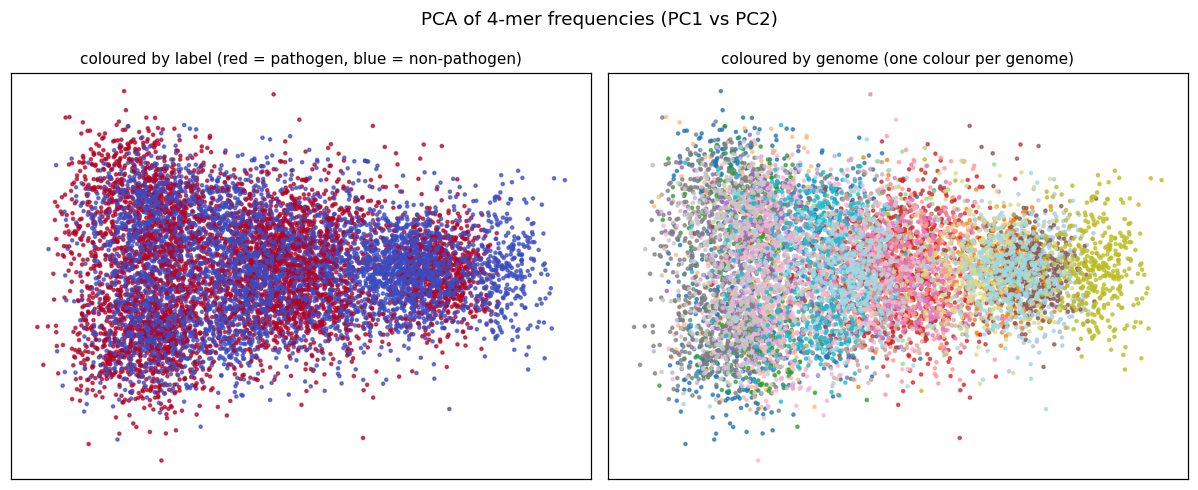

In [9]:
def pca_embed(k, n=50):
    Z = StandardScaler().fit_transform(FREQ[k])
    p = PCA(n_components=n, random_state=SEED).fit(Z)
    return Z, p, p.transform(Z)

PCA_RES = {k: pca_embed(k) for k in (4, 6)}
for k in (4, 6):
    ev = PCA_RES[k][1].explained_variance_ratio_
    print(f"k={k}: PC1 {ev[0]:.1%}, PC2 {ev[1]:.1%}, first 50 PCs together {ev.sum():.1%}")

def scatter2(E, title, idx=None):
    idx = np.arange(len(E)) if idx is None else idx
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    ax[0].scatter(E[idx, 0], E[idx, 1], c=y[idx], s=4, cmap="coolwarm", alpha=0.7)
    ax[0].set_title("coloured by label (red = pathogen, blue = non-pathogen)", fontsize=10)
    ax[1].scatter(E[idx, 0], E[idx, 1], c=pd.factorize(genome[idx])[0], s=4, cmap="tab20", alpha=0.7)
    ax[1].set_title("coloured by genome (one colour per genome)", fontsize=10)
    for a in ax: a.set_xticks([]); a.set_yticks([])
    fig.suptitle(title); plt.tight_layout(); plt.show()

scatter2(PCA_RES[4][2][:, :2], "PCA of 4-mer frequencies (PC1 vs PC2)")

### Putting numbers on it

Two numbers per row:
- **silhouette_genome**: how tightly fragments group by genome (about 0 = no groups, higher = clearer groups).
- **cross_genome_label_purity**: for each fragment, look at its nearest neighbours *from other genomes* and check how often they share its label. 0.5 is chance, and values near 1 would mean the class is shared across genomes, which is what a classifier would need.

**GC check:** the second half of the table repeats the numbers after the effect of fragment GC content has been subtracted from every k-mer frequency. If purity falls toward 0.5, the class signal was mostly GC. The matched-genus GC table is printed first for context.

In [10]:
def cross_genome_purity(Z, n_nb=10, pool=500):
    nn = NearestNeighbors(n_neighbors=min(pool, len(Z) - 1) + 1).fit(Z)
    idx = nn.kneighbors(Z, return_distance=False)[:, 1:]
    scores = []
    for i, nb in enumerate(idx):
        nb = nb[genome[nb] != genome[i]][:n_nb]
        if len(nb): scores.append((y[nb] == y[i]).mean())
    return float(np.mean(scores))

def regress_out(Z, x):
    xc = (x - x.mean())[:, None]
    beta = (xc * Z).sum(0) / (xc ** 2).sum()
    return Z - xc * beta

genus_has_both = df.groupby("genus").label.nunique()
pairs = genus_has_both[genus_has_both == 2].index
print("Mean fragment GC in matched genera:")
display(df[df.genus.isin(pairs)].pivot_table(index="genus", columns="label_name", values="gc", aggfunc="mean").round(4))

rows = []
for k in (4, 6):
    Z, _, P = PCA_RES[k]
    P_nogc = PCA(n_components=50, random_state=SEED).fit_transform(regress_out(Z, gc))
    for name, E in ((f"k={k}, original", P), (f"k={k}, GC removed", P_nogc)):
        rows.append(dict(space=name,
                         silhouette_genome=round(silhouette_score(E, genome, sample_size=min(3000, len(E)), random_state=SEED), 3),
                         cross_genome_label_purity=round(cross_genome_purity(E), 3)))
display(pd.DataFrame(rows))

Mean fragment GC in matched genera:


label_name,non_pathogen,pathogen
genus,,
Bacillus,0.4335,0.3552
Corynebacterium,0.5389,0.5335
Escherichia,0.5072,0.5035
Listeria,0.3744,0.3775
Pseudomonas,0.6165,0.6685
Streptococcus,0.3919,0.3855


,space,silhouette_genome,cross_genome_label_purity
0,"k=4, original",0.028,0.368
1,"k=4, GC removed",0.015,0.401
2,"k=6, original",0.038,0.346
3,"k=6, GC removed",0.028,0.366


## Summary of Tasks 1 and 2 (results from the real dataset)

| Step | Result | Takeaway |
|---|---|---|
| k comparison | Share of the vocabulary one fragment uses: 99.2% (k=3), 89.4% (k=4), 19.5% (k=6), 1.5% (k=8). Every word occurs somewhere in the corpus. | k=4 is dense, k=6 sparse, k=8 too sparse. Use k=4 for plots. |
| Word frequencies | 4-mers: AAAA and TTTT most common (~93k each), CTAG rarest (12.8k). 6-mers: 17 of the 20 rarest contain CTAG. | AT-rich and GC-rich word families. CTAG avoidance is a general bacterial pattern, not a pathogen marker. |
| GC content | Pathogen 47.3% vs non-pathogen 50.7% (spread about 11.5 points). Within matched genera the gap is under 1 point in 4 of 6 pairs (Bacillus -8, Pseudomonas +5). | Classes overlap heavily. No consistent GC difference within a genus. |
| GC skew, word diversity | Same in both classes (distinct 4-mers 228 vs 230, distinct 6-mers 800 vs 799). | No signal. |
| Word differences | Pathogen-enriched words are AT-rich, non-pathogen-enriched are GC-rich. Best p before correction: 0.04 (k=4), 0.004 (k=6). | None survive multiple-test correction. No marker word. |
| PCA | PC1 is a smooth GC/organism gradient. Red and blue points overlap almost completely. | No class separation. |
| Cross-genome label purity (0.5 = chance) | k=4: 0.37, GC removed 0.40. k=6: 0.35, GC removed 0.37. | Below chance, so nearest neighbours from other genomes tend to have the opposite label (probably genus partners). Removing GC reveals no hidden signal. |
| Silhouette by genome | 0.015 to 0.038 | Genomes overlap along a gradient and do not form tight groups. |

**Overall:** k-mer frequencies in this dataset mostly reflect GC content and relatedness between organisms, not pathogenicity. k=6 adds nothing over k=4.